In [1]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pickle

In [2]:
PATH = "C:/Users/henry/Desktop/UCL/ExtraQNLPWork/qNLP_Efficiency/qnlp_in_practice/"

rp_noise_random_path = "code/rp_runs/noise_random/"
rp_noise_pretrain_path = "code/rp_runs/noise_pretrained/"
rp_sim_random_path = "code/rp_runs/sim_random/"
rp_sim_pretrain_path = "code/rp_runs/sim_pretrained/"
mc_noise_random_path = "code/mc_runs/noise_random/"
mc_noise_pretrain_path = "code/mc_runs/noise_pretrained/"
mc_sim_random_path = "code/mc_runs/sim_random/"
mc_sim_pretrain_path = "code/mc_runs/sim_pretrained/"

In [3]:
def get_data_from_path(directory_path, niter=100, test_iters=11, mean=True, first_N_runs=100):
    if "C:/" not in directory_path:
        directory_path = PATH+ directory_path
    files = [directory_path+ i for i in os.listdir(directory_path)]

    cost_histories = np.zeros(shape=(len(files), niter))
    error_train_histories = np.zeros(shape=(len(files), niter))
    error_test_histories = np.zeros(shape=(len(files), test_iters))

    for f_index, file in enumerate(files):
        if f_index >= first_N_runs:
            print(f"Exiting after {first_N_runs} runs")
            break
        with open(file, 'rb') as file:
            data = pickle.load(file)

        if len(data['error_history']) != niter:
            print(file.name + f" Does not have {niter} iterations!")
            break

        cost_histories[f_index, :] = data['func_history']
        error_train_histories[f_index, :] = data['error_history'] 
        error_test_histories[f_index, :] = data['test_error_list']

        if 'iters_selected' in data.keys():
            iters_selected = data['iters_selected']
        else:
            iters_selected = np.arange(niter)

    if mean:
        cost_history_mean = cost_histories.mean(0)
        error_train_history_mean = error_train_histories.mean(0)
        error_test_history_mean = error_test_histories.mean(0)
    else:
        cost_history_mean = cost_histories
        error_train_history_mean = error_train_histories
        error_test_history_mean = error_test_histories

    return {'cost':cost_history_mean, 
            'train_error':error_train_history_mean, 
            'test_error':error_test_history_mean, 
            'test_iterations':iters_selected}


def plot_random_pretrain_comparisons(random_dict, pretrained_dict, title, saving):
    fig, ax1 = plt.subplots(figsize=(13, 8))

    ax1.plot(range(len(random_dict['cost'])), random_dict['cost']/random_dict['cost'][0], '-k', markersize=4, label='random cost', alpha=0.5)
    ax1.plot(range(len(pretrained_dict['cost'])), pretrained_dict['cost']/pretrained_dict['cost'][0], '-k', markersize=4, label='pretrained cost', alpha=1)
    ax1.set_ylabel(r"Cost", fontsize='x-large')
    ax1.set_xlabel(r"SPSA~iterations", fontsize='x-large')
    ax1.legend(loc='upper center', fontsize='x-large')

    ax2 = ax1.twinx()
    ax2.set_ylabel(r"Error in \%", fontsize='x-large')
    ax2.plot(range(len(random_dict['train_error'])), random_dict['train_error'], '-g', markersize=4, label='random training error', alpha=0.5)
    ax2.plot(range(len(pretrained_dict['train_error'])), pretrained_dict['train_error'], '-g', markersize=4, label='pretrained training error', alpha=1)

    ax2.plot(random_dict['test_iterations'], random_dict['test_error'], 'b', markersize=7, label='random testing error', alpha=0.5)
    ax2.plot(pretrained_dict['test_iterations'], pretrained_dict['test_error'], 'b', markersize=7, label='pretrained testing error', alpha=1)
    ax2.legend(loc='upper right', fontsize='x-large')

    plt.title(title, fontsize='x-large')
    if saving: 
        plt.savefig(title, dpi=300, facecolor='white') 
    plt.show()

# RP Experiments 

## RP Noise Experiments

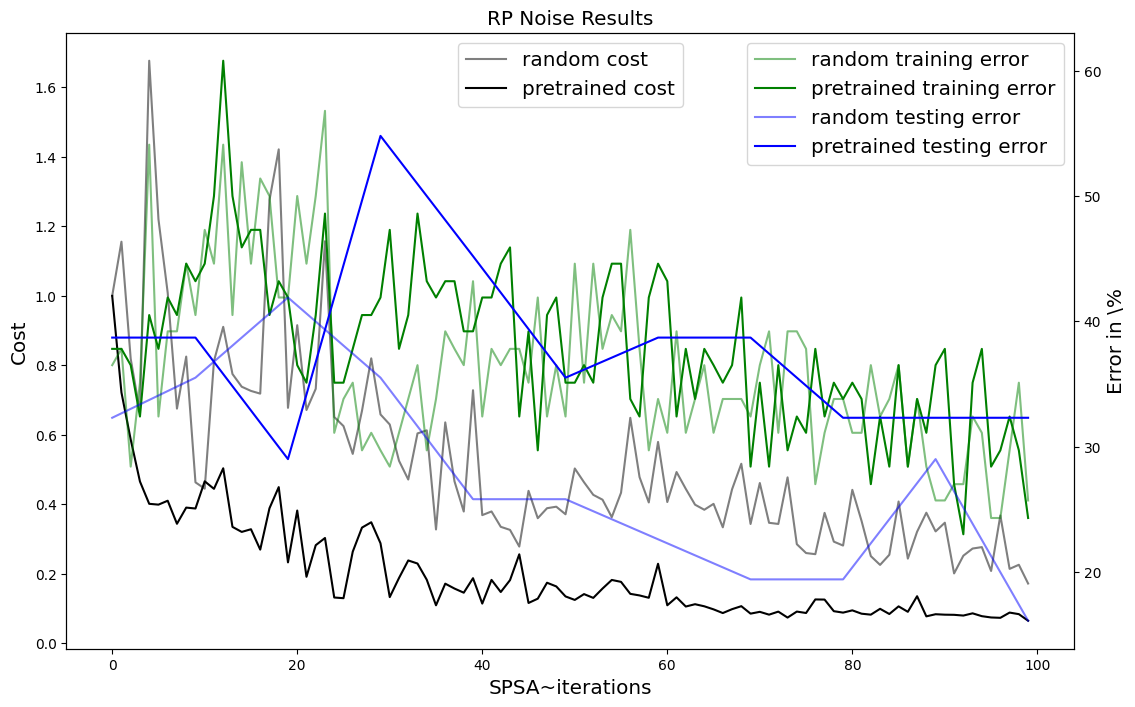

In [4]:
rp_n_rand = get_data_from_path(rp_noise_random_path, 100) # maybe needs , 11) added!
rp_n_pre = get_data_from_path(rp_noise_pretrain_path, 100)

plot_random_pretrain_comparisons(rp_n_rand, rp_n_pre, 'RP Noise Results', True)

## RP Simulated Experiments

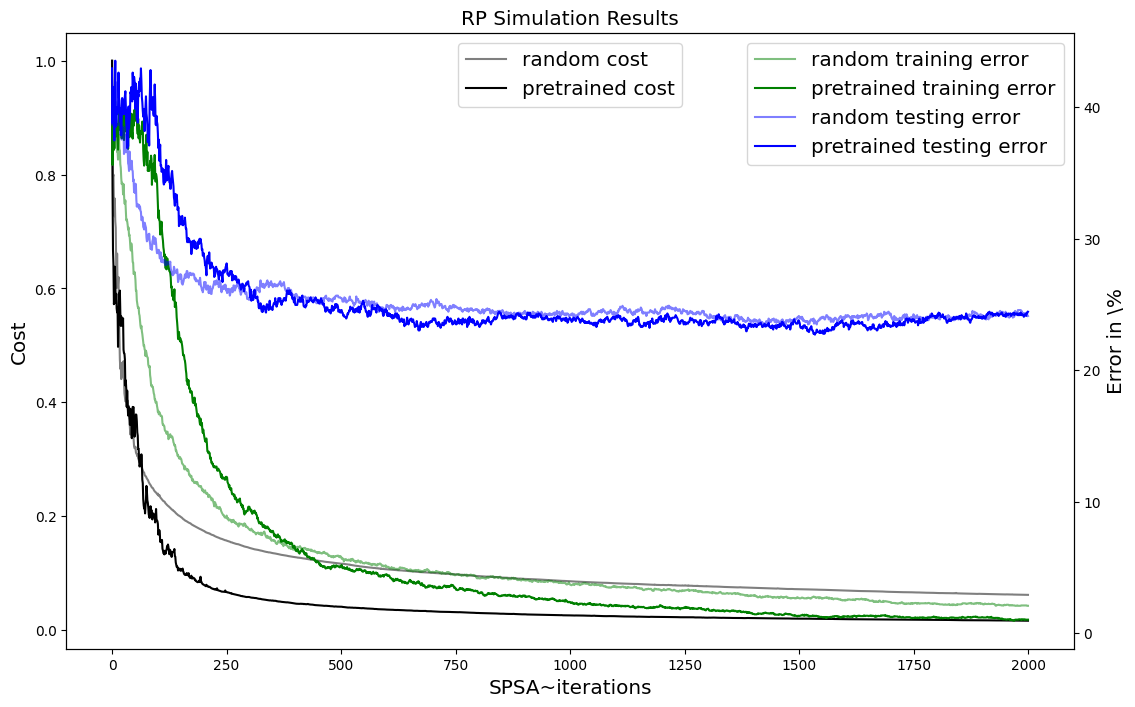

In [31]:
rp_s_rand = get_data_from_path(rp_sim_random_path, 2000, 2000)
rp_s_pre = get_data_from_path(rp_sim_pretrain_path, 2000, 2000)

plot_random_pretrain_comparisons(rp_s_rand, rp_s_pre, 'RP Simulation Results', True)

# MC Tasks

## MC Noise Experiments

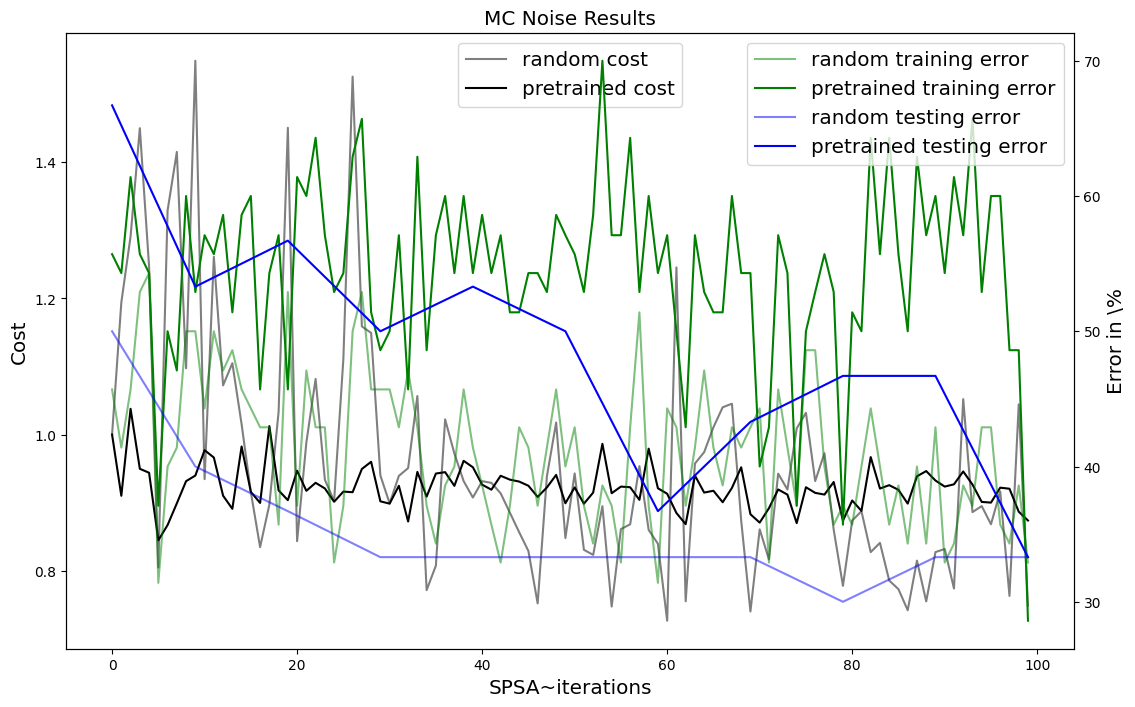

In [5]:
random_cost, random_train, random_test, random_iters_selected = get_data_from_path(mc_noise_random_path, 100, 11)
pretrained_cost, pretrained_train, pretrained_test, pretrained_iters_selected = get_data_from_path(mc_noise_pretrain_path, 100, 11)

mc_n_rand = get_data_from_path(mc_noise_random_path, 100, 11)
mc_n_pre = get_data_from_path(mc_noise_pretrain_path, 100, 11)

plot_random_pretrain_comparisons(mc_n_rand, mc_n_pre, 'MC Noise Results', True)

## MC Simulated Experiments

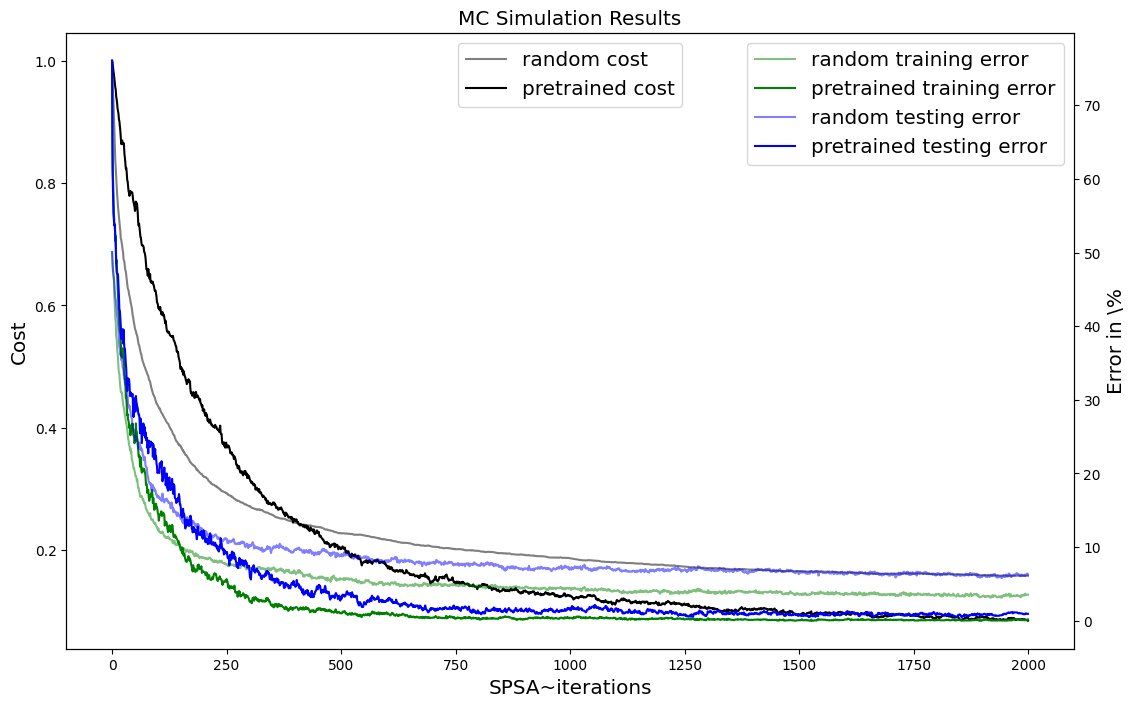

In [32]:
mc_s_rand = get_data_from_path(mc_sim_random_path, 2000, 2000)
mc_s_pre = get_data_from_path(mc_sim_pretrain_path, 2000, 2000)

plot_random_pretrain_comparisons(mc_s_rand, mc_s_pre, 'MC Simulation Results', True)